In [6]:
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.2 MB 2.8 MB/s eta 0:00:03
   ------- -------------------------------- 1.6/8.2 MB 2.7 MB/s eta 0:00:03
   ---------- ----------------------------- 2.1/8.2 MB 2.8 MB/s eta 0:00:03
   -------------- ------------------------- 2.9/8.2 MB 2.9 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.2 MB 3.0 MB/s eta 0:00:02
   -------------------- ------------------- 4.2/8.2 MB 3.1 MB/s eta 0:00:02
   ------------------------ --------------- 5.0/8.2 MB 3.1 MB/s eta 0:00:02
   -------------------------- ------------- 5.5/8.2 MB 3.1 MB/s eta 0:00:01
   ----------------------------- ---------- 6.0/8.2 MB 3.0 MB/s eta 0:00:01
   --------------------------------- ------ 6.8/8.2 MB 3.0 MB/s eta 0:00:01
   ---------------------

In [17]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Ensure the CustomLinearRegression class is freshly loaded
class CustomLinearRegression:
    def __init__(self, learning_rate=0.1, iterations=1000):
        self.lr = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.loss_history=[]

        for _ in range(self.iterations):
            y_predicted = np.dot(X, self.weights) + self.bias

            current_loss = np.mean((y_predicted - y) **2)
            self.loss_history.append(current_loss)
            
            # Math checks out: shapes must match perfectly here
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

In [18]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(r"C:\Users\hp\Downloads\NIFTY Dataset\National_Stock_Exchange_of_India_Ltd.csv")

cols_to_clean = ['Open', 'High', 'Low', 'LTP', 'Volume (lacs)', 'Turnover (crs.)', '52w H', '52w L']

for col in cols_to_clean:
    if df[col].dtype == 'object':
        df[col] = df[col].str.replace(',','').astype(float)

X=df[['Open', 'High', 'Low', 'Volume (lacs)']].values
y=df['LTP'].values

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=1)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
model = CustomLinearRegression(learning_rate=0.1, iterations=1000)
model.fit(X_train_scaled, y_train)
print("Completed!")
print(f"Learned Weights (Open,High,Low,Volume) : {model.weights}")

Completed!
Learned Weights (Open,High,Low,Volume) : [1736.37885891 1795.8001931  1806.62140312   -5.02207358]


In [20]:
predictions = model.predict(X_test_scaled)

print("\n INTRADAY PRICE PREDICTION ")
for i in range(5):
    print(f"Actual LTP: ₹{y_test[i]:<8.2f} | Predicted: ₹{predictions[i]:<8.2f} | Error: ₹{predictions[i] - y_test[i]:>+6.2f}")
    


 INTRADAY PRICE PREDICTION 
Actual LTP: ₹630.00   | Predicted: ₹651.01   | Error: ₹+21.01
Actual LTP: ₹202.50   | Predicted: ₹204.06   | Error: ₹ +1.56
Actual LTP: ₹767.25   | Predicted: ₹775.46   | Error: ₹ +8.21
Actual LTP: ₹470.00   | Predicted: ₹469.46   | Error: ₹ -0.54
Actual LTP: ₹661.00   | Predicted: ₹663.65   | Error: ₹ +2.65


<big>MSE</big> 

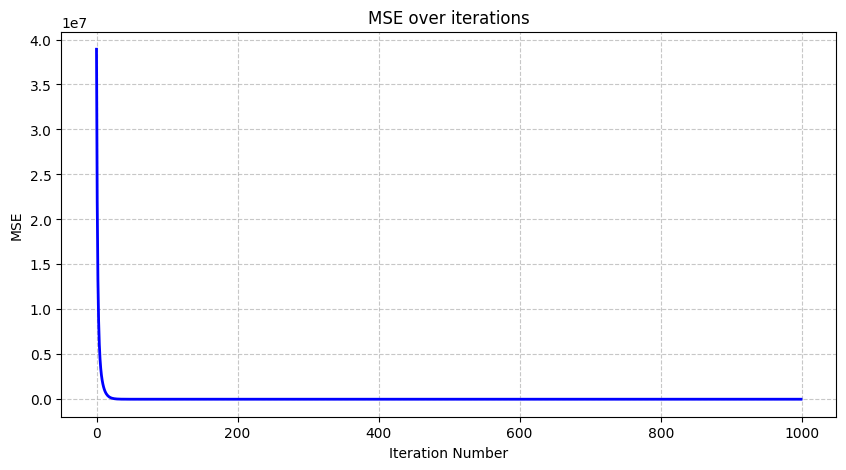

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(range(model.iterations), model.loss_history, color = 'blue', linewidth=2)
plt.title("MSE over iterations")
plt.xlabel('Iteration Number')
plt.ylabel('MSE')
plt.grid(True, linestyle='--',alpha=0.7)
plt.show()

<big>SCATTERPLOT</big>

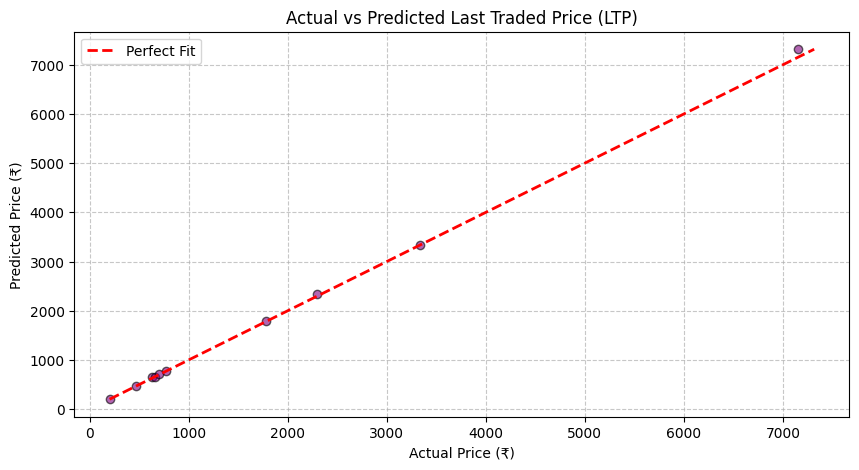

In [22]:
plt.figure(figsize=(10, 5))
plt.scatter(y_test, predictions, color='purple', alpha=0.6, edgecolors='black')

# Create the perfect prediction line
max_val = max(max(y_test), max(predictions))
min_val = min(min(y_test), min(predictions))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Fit')

plt.title('Actual vs Predicted Last Traded Price (LTP)')
plt.xlabel('Actual Price (₹)')
plt.ylabel('Predicted Price (₹)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

<big>RESIDUAL PLOT</big>

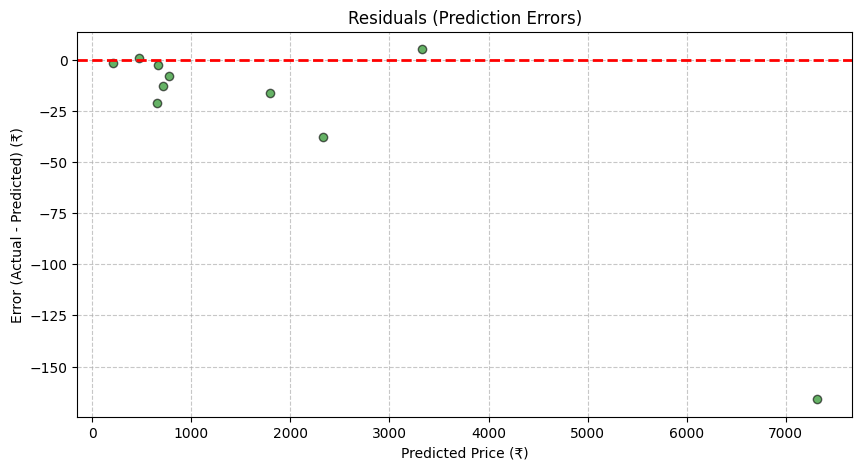

In [23]:
residuals = y_test - predictions
plt.figure(figsize=(10, 5))
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.scatter(predictions, residuals, color='green', alpha=0.6, edgecolors='black')
plt.title('Residuals (Prediction Errors)')
plt.xlabel('Predicted Price (₹)')
plt.ylabel('Error (Actual - Predicted) (₹)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

<font size="5">RANDOM FOREST REGRESSOR</font>

In [24]:
import numpy as np

class CustomRegressionTree:
    def __init__(self, max_depth=3):
        self.max_depth = max_depth
        self.tree = None

    def fit(self,X,y,depth=0):
        if depth>= self.max_depth or len(y)<2 or len(np.unique(y))==1:
            return np.mean(y)

        best_feat, best_thresh, best_var = None,None,float('inf')

        n_features = X.shape[1]
        features = np.random.choice(n_features, max(1, int(n_features/2)), replace=False)

        for feat in features:
            thresholds = np.unique(X[:,feat])
            for t in thresholds:
                left_mask = X[:,feat]<= t
                right_mask = X[:, feat] > t
                if sum(left_mask) ==0 or sum(right_mask) == 0: continue

                var_left = np.var(y[left_mask]) * sum(left_mask)
                var_right = np.var(y[right_mask]) * sum(right_mask)
                total_var = var_left + var_right

                if total_var < best_var:
                    best_var, best_feat, best_thresh = total_var, feat, t

        if best_feat is None: return np.mean(y)

        left_mask = X[:, best_feat] <= best_thresh
        right_mask = X[:, best_feat] > best_thresh

        return{
                    'feature' : best_feat,
                    'threshold' : best_thresh,
                    'left' : self.fit(X[left_mask], y[left_mask], depth+1),
                    'right' : self.fit(X[right_mask], y[right_mask], depth+1)
        }

    def predict_row(self,row,node):
            if not isinstance(node,dict): return node
            if row[node['feature']] <= node['threshold']:
                return self.predict_row(row, node['left'])
            else:
                return self.predict_row(row, node['right'])

    def predict(self, X):
            return np.array([self.predict_row(row, self.tree) for row in X])

class CustomRandomForest:
    def __init__(self,n_trees=10,max_depth=3):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.trees = []

    def fit(self,X,y):
        self.trees = []
        for _ in range(self.n_trees):
            tree = CustomRegressionTree(max_depth=self.max_depth)
            indices = np.random.choice(len(X), len(X), replace=True)
            tree.tree = tree.fit(X[indices], y[indices])
            self.trees.append(tree)

    def predict(self,X):
        tree_preds = np.array([tree.predict(X) for tree in self.trees])
        return np.mean(tree_preds, axis=0)
        


In [31]:
custom_rf = CustomRandomForest(n_trees=500, max_depth=20)

print("Training the model..")
custom_rf.fit(X_train_scaled, y_train)

custom_preds = custom_rf.predict(X_test_scaled)
custom_mae = np.mean(np.abs(y_test - custom_preds))

print(f"MAE : ₹{custom_mae:.2f}")

Training the model..
MAE : ₹440.31


In [32]:
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Ensure you have predictions from BOTH custom models
lr_preds = model.predict(X_test_scaled)
rf_preds = custom_rf.predict(X_test_scaled)

# 2. Calculate metrics
metrics = {
    "Model": ["Custom Linear Regression", "Custom Random Forest"],
    "MAE (₹)": [
        mean_absolute_error(y_test, lr_preds),
        mean_absolute_error(y_test, rf_preds)
    ],
    "RMSE (₹)": [
        np.sqrt(mean_squared_error(y_test, lr_preds)),
        np.sqrt(mean_squared_error(y_test, rf_preds))
    ],
    "R-Squared": [
        r2_score(y_test, lr_preds),
        r2_score(y_test, rf_preds)
    ]
}

# 3. Display as a clean DataFrame
comparison_df = pd.DataFrame(metrics)
comparison_df.set_index("Model", inplace=True)
print("\n--- Model Performance Comparison ---")
display(comparison_df.round(2))


--- Model Performance Comparison ---


,MAE (₹),RMSE (₹),R-Squared
Model,,,
Custom Linear Regression,27.22,54.74,1.00
Custom Random Forest,440.31,869.83,0.81


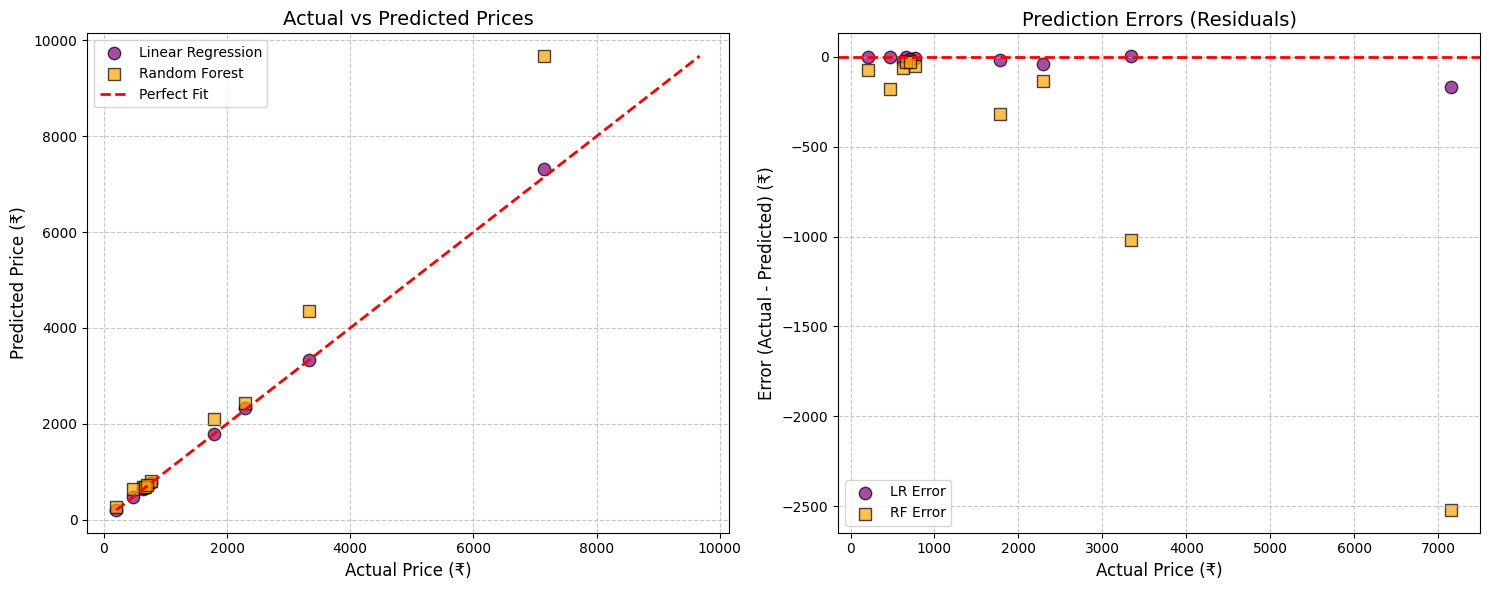

In [33]:
import matplotlib.pyplot as plt

# 1. Setup the figure layout
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Ensure you have predictions from both models
lr_preds = model.predict(X_test_scaled)
rf_preds = custom_rf.predict(X_test_scaled)

# 2. Actual vs Predicted Scatter Plot
max_val = max(max(y_test), max(lr_preds), max(rf_preds))
min_val = min(min(y_test), min(lr_preds), min(rf_preds))

axes[0].scatter(y_test, lr_preds, color='purple', alpha=0.7, edgecolors='black', s=80, label='Linear Regression')
axes[0].scatter(y_test, rf_preds, color='orange', alpha=0.7, edgecolors='black', marker='s', s=80, label='Random Forest')
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Fit')
axes[0].set_title('Actual vs Predicted Prices', fontsize=14)
axes[0].set_xlabel('Actual Price (₹)', fontsize=12)
axes[0].set_ylabel('Predicted Price (₹)', fontsize=12)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)

# 3. Residuals (Error) Scatter Plot
lr_residuals = y_test - lr_preds
rf_residuals = y_test - rf_preds

axes[1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[1].scatter(y_test, lr_residuals, color='purple', alpha=0.7, edgecolors='black', s=80, label='LR Error')
axes[1].scatter(y_test, rf_residuals, color='orange', alpha=0.7, edgecolors='black', marker='s', s=80, label='RF Error')
axes[1].set_title('Prediction Errors (Residuals)', fontsize=14)
axes[1].set_xlabel('Actual Price (₹)', fontsize=12)
axes[1].set_ylabel('Error (Actual - Predicted) (₹)', fontsize=12)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

# Display the charts
plt.tight_layout()
plt.show()

In [2]:
!pip install gradio

Defaulting to user installation because normal site-packages is not writeable
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
   ---------------------------------------- 0.0/31.3 MB ? eta -:--:--
   - -------------------------------------- 0.8/31.3 MB 4.2 MB/s eta 0:00:08
   -- ------------------------------------- 2.1/31.3 MB 5.1 MB/s eta 0:00:06
   ---- ----------------------------------- 3.4/31.3 MB 5.8 MB/s eta 0:00:05
   ------- -------------------------------- 5.5/31.3 MB 6.7 MB/s eta 0:00:04
   ---------- ----------------------------- 8.1/31.3 MB 7.9 MB/s eta 0:00:03
   -------------- ------------------------- 11.5/31.3 MB 9.3 MB/s eta 0:00:03
   -------------------- ------------------- 15.7/31.3 MB 10.8 MB/s eta 0:00:02
   -------------------------- ------------- 21.0/31.3 MB 12.5 MB/s eta 0:00:01
   ----------------------------------- ---- 27.8/31.3 MB 14.8 MB/s eta 0:00:01
   ---------------------------------------- 31.3/31.3 MB 14.9 MB/s  0:00:02
   -

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
import gradio as gr
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# --- 1. The Custom Algorithm ---
class CustomLinearRegression:
    def __init__(self, learning_rate=0.05, iterations=2000):
        self.lr = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        for _ in range(self.iterations):
            y_pred = np.dot(X, self.weights) + self.bias
            dw = (1 / n_samples) * np.dot(X.T, (y_pred - y))
            db = (1 / n_samples) * np.sum(y_pred - y)
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

# --- 2. Background Data Prep & Training ---
print("Training model in the background...")
df = pd.read_csv(r"C:\Users\hp\Downloads\NIFTY Dataset\National_Stock_Exchange_of_India_Ltd.csv")
cols_to_clean = ['Open', 'High', 'Low', 'LTP', 'Volume (lacs)']
for col in cols_to_clean:
    if df[col].dtype == 'object':
        df[col] = df[col].astype(str).str.replace(',', '').astype(float)

X = df[['Open', 'High', 'Low', 'Volume (lacs)']].values
y = df['LTP'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

lr_model = CustomLinearRegression()
lr_model.fit(X_scaled, y)
print("Model Ready! Launching UI...")

# --- 3. The UI Bridge Function ---
def predict_stock_price(open_price, high_price, low_price, volume):
    # Package the user's inputs into a 2D array
    user_inputs = np.array([[open_price, high_price, low_price, volume]])
    
    # Scale the inputs using the exact same scaler from training
    scaled_inputs = scaler.transform(user_inputs)
    
    # Make the prediction
    prediction = lr_model.predict(scaled_inputs)[0]
    
    return f"₹{prediction:.2f}"

# --- 4. Build and Launch the Gradio App ---
ui = gr.Interface(
    fn=predict_stock_price,
    inputs=[
        gr.Number(label="Open Price (₹)", value=2400.0),
        gr.Number(label="High Price (₹)", value=2450.0),
        gr.Number(label="Low Price (₹)", value=2380.0),
        gr.Number(label="Volume (lacs)", value=15.5)
    ],
    outputs=gr.Text(label="Predicted Last Traded Price (LTP)"),
    title="📈 Custom Quantitative Pricing Model",
    description="Enter the intraday metrics for an NSE stock to generate a pricing prediction using a custom-built Gradient Descent algorithm. \n\n*Note: This model currently uses same-day metrics and is for educational structural analysis, not live forward-looking trading.*",
    theme="default"
)

# Launch directly in the notebook
ui.launch(share=False)

Training model in the background...
Model Ready! Launching UI...


C:\Users\hp\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\gradio\interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
